# 01 · The bench: what each retraining policy costs and buys

**Block 2 · W44, notebook 1 of 2.** A park of hourly series is served continuously by a simple model. Ten
retraining policies decide, at every hour and for every series, whether to refit. This notebook builds the bench
piece by piece, reproduces the plan's table, and shows why stability is a contract with **two** clauses that
pull in opposite directions.

| § | Question | Short answer |
|---|---|---|
| 1 | What does the park look like? | Abrupt level breaks plus a slow drift of the daily profile's amplitude. |
| 2 | What is served, and with which data? | A window mean + daily profile, fit on data closed 48 h ago. |
| 3 | How do we score a policy? | Three families: accuracy (MASE), cost (refits), stability (churn, jumps). |
| 4 | What do the ten policies give? | The plan's table, reproduced to the digit. |
| 5 | What does ignoring the closing lag cost? | About +6% of MASE, the same for every policy. |
| 6 | Can one cadence satisfy every stability clause? | No: jump size and jump frequency move in opposite directions. |

> **How to read this notebook.** Callouts follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a measured experiment ·
> **Watch out**, the trap to avoid · **Takeaway**, the note to keep.

In [1]:
import logging, warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from w44_retraining import viz
from w44_retraining.park import ParkSpec, make_park
from w44_retraining.model import fit_window, forecast
from w44_retraining.metrics import seasonal_scale
from w44_retraining.harness import Bench, Calendar, Cusum, KLDebt, run, plan_policies, total_cost

viz.setup()
export = viz.exporter("../figures")
np.set_printoptions(precision=4, suppress=True)
bench = Bench()
park = make_park()                        # 120 series x 2,400 hourly steps, seed 44 (the plan's park)
SERIES, BREAK = 43, 1078                  # a series with a clear level break, used for every illustration
print(f"park: {park.y.shape[0]} series x {park.y.shape[1]} steps, {park.cps.sum()} level breaks "
      f"({park.cps.sum(axis=1).mean():.1f} per series)")

park: 120 series x 2400 steps, 448 level breaks (3.7 per series)


## 1. The park: two drifts of different nature

**Question.** What kind of change does a retraining policy have to follow?

Each series is `level + daily profile x amplitude + noise`:

- the **level** is piecewise constant: at random times (about one every 600 hours) it jumps by a random amount.
  That is an **abrupt** change, a *break*;
- the **daily profile** (24 hourly values) is fixed in shape, but its **amplitude** drifts slowly along a
  sinusoid of period 2,400 hours, between 0.65 and 1.35 times its base size. That is a **gradual** change: at no
  moment does anything "happen".

> **Intuition.** A drift detector looks for moments when something happens. A break is such a moment; a slowly
> swelling daily cycle is not. The bench is built so that a policy reacting only to breaks is blind to half of
> the drift.

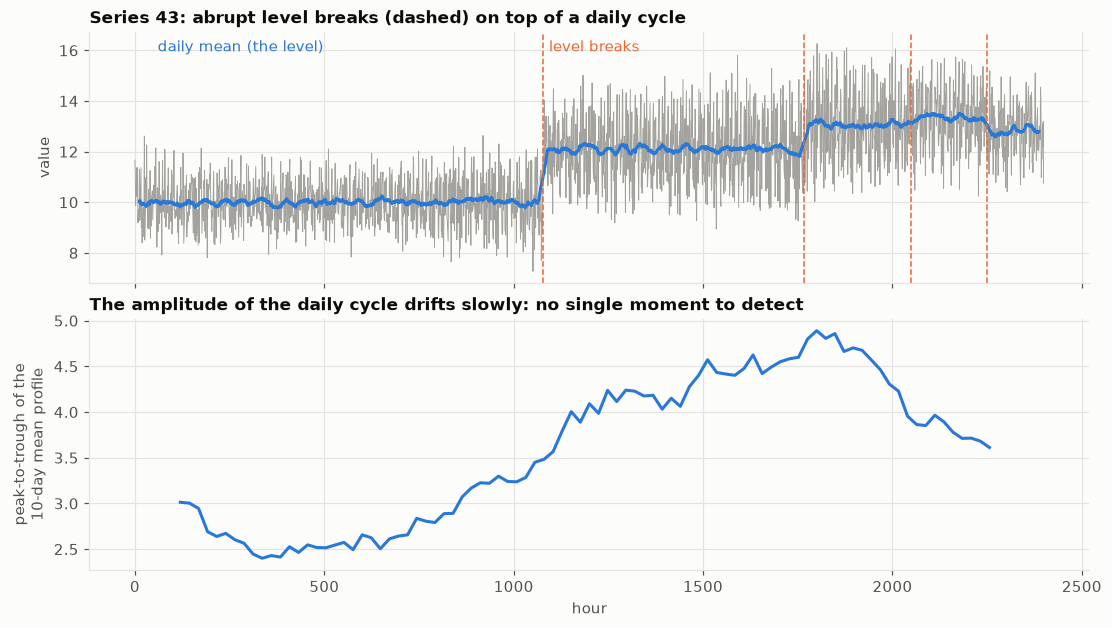

In [2]:
y = park.y[SERIES]
t = np.arange(len(y))
cps = np.nonzero(park.cps[SERIES])[0]
day = np.convolve(y, np.ones(24) / 24, mode="same")     # daily mean: removes the profile, shows the level
fig, axs = plt.subplots(2, 1, figsize=(10, 5.6), layout="constrained", sharex=True)
axs[0].plot(t, y, color=viz.MUTED, lw=0.6)
axs[0].plot(t[12:-12], day[12:-12], color=viz.BLUE, lw=2)
for c in cps:
    axs[0].axvline(c, color=viz.ORANGE, lw=1, ls="--")
axs[0].text(cps[0] + 15, y.max() - 0.3, "level breaks", color=viz.ORANGE)
axs[0].text(60, y.max() - 0.3, "daily mean (the level)", color=viz.BLUE)
axs[0].set_title(f"Series {SERIES}: abrupt level breaks (dashed) on top of a daily cycle")
axs[0].set_ylabel("value")
amp = np.array([np.ptp(y[s:s + 240].reshape(10, 24).mean(axis=0)) for s in range(0, len(y) - 240, 24)])
axs[1].plot(np.arange(0, len(y) - 240, 24) + 120, amp, color=viz.BLUE)
axs[1].set_title("The amplitude of the daily cycle drifts slowly: no single moment to detect")
axs[1].set_ylabel("peak-to-trough of the\n10-day mean profile")
axs[1].set_xlabel("hour")
export(fig, "park_two_drifts"); plt.show()

## 2. What is served, and with which data

**Question.** What does "refit now" actually mean in production?

The served model is deliberately simple: over a **window of W = 240 hours** (10 days) it estimates a level (the
window mean) and a daily profile (the mean residual at each hour of the day). The forecast for the next H = 24
hours is `level + profile[hour of day]`.

The important detail is the **closing lag d = 48**: actuals are only final ("closed") two days after the fact
(late meter readings, corrections, reconciliations). So a model refit at hour t is fit on the window that ends at
**t - 48**, never at t.

> **Example.** Below, a refit at hour 1,100, just after the break at 1,078. The window the model may use ends
> at 1,052: it does not contain the break at all, and the served level stays at the old value. Even the leaky
> backtest, whose window ends at 1,100, barely moves: 22 post-break hours out of 240 shift a window mean by
> about a tenth of the break. Keep this in mind for notebook 2.

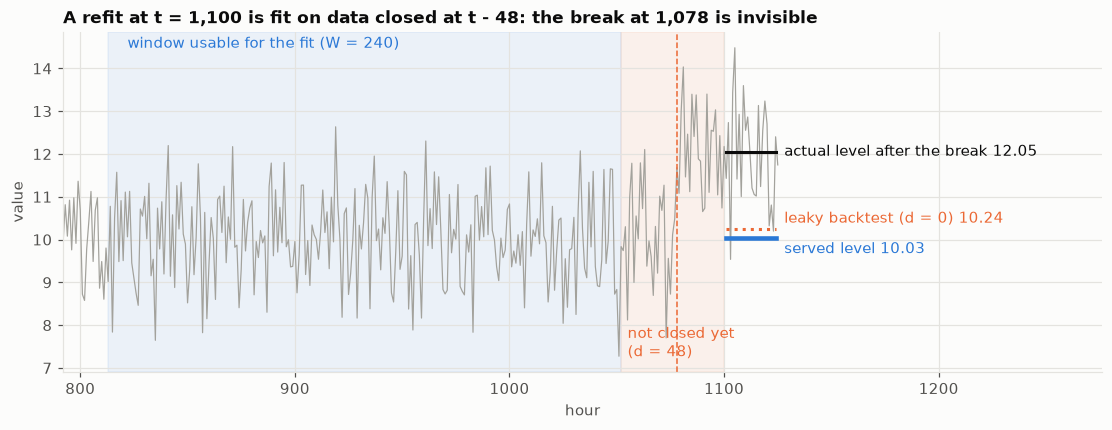

served level 10.025 | leaky level 10.238 | actual level after the break 12.052


In [3]:
t_now = 1100
mu, prof, _ = fit_window(park.y, t_now - bench.d, bench.w, 24)
mu_leak, _, _ = fit_window(park.y, t_now, bench.w, 24)
after = y[BREAK + 1 : t_now + bench.h + 1].mean()
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
lo, hi = t_now - bench.d - bench.w - 20, t_now + bench.h + 2
ax.plot(t[lo:hi], y[lo:hi], color=viz.MUTED, lw=0.8)
ax.axvspan(t_now - bench.d - bench.w + 1, t_now - bench.d, color=viz.BLUE, alpha=0.08)
ax.axvspan(t_now - bench.d, t_now, color=viz.ORANGE, alpha=0.08)
ax.axvline(BREAK, color=viz.ORANGE, ls="--", lw=1)
seg = np.array([t_now + 1, t_now + bench.h])
ax.plot(seg, [mu[SERIES]] * 2, color=viz.BLUE, lw=3)
ax.plot(seg, [mu_leak[SERIES]] * 2, color=viz.ORANGE, lw=2, ls=":")
ax.plot(seg, [after] * 2, color=viz.TEXT, lw=2)
ax.text(seg[1] + 4, mu[SERIES] - 0.25, f"served level {mu[SERIES]:.2f}", color=viz.BLUE, va="center")
ax.text(seg[1] + 4, mu_leak[SERIES] + 0.25, f"leaky backtest (d = 0) {mu_leak[SERIES]:.2f}", color=viz.ORANGE,
        va="center")
ax.text(seg[1] + 4, after, f"actual level after the break {after:.2f}", color=viz.TEXT, va="center")
ax.text(t_now - bench.d - bench.w + 10, y[lo:hi].max(), "window usable for the fit (W = 240)", color=viz.BLUE)
ax.text(t_now - bench.d + 3, y[lo:hi].min(), "not closed yet\n(d = 48)", color=viz.ORANGE)
ax.set_xlim(lo, hi + 150)
ax.set_title("A refit at t = 1,100 is fit on data closed at t - 48: the break at 1,078 is invisible")
ax.set_xlabel("hour"); ax.set_ylabel("value")
export(fig, "closing_lag_timeline"); plt.show()
print(f"served level {mu[SERIES]:.3f} | leaky level {mu_leak[SERIES]:.3f} | actual level after the break {after:.3f}")

> **Watch out.** A backtest that fits on the window ending at t (the dotted forecast) gives the model 48 hours of
> information it will never have in production. Section 5 prices this leak.

## 3. How a policy is scored: three families, never one

**Accuracy: MASE.** The mean absolute error of the 24-hour forecast, divided by the series' **scale**: the mean
of `|y_t - y_{t-24}|`, the error a "same hour yesterday" forecast would make. MASE = 1 means as good as that
naive rule on average; lower is better. The scale is written with an explicit lag, `y[24:] - y[:-24]`, not
`np.diff(y, n=24)`, which would be a 24th-order difference.

**Cost: refits per series.** Over the 2,064 served hours.

**Stability.** Between two consecutive hours, the forecasts of the same 23 target hours overlap. The **revision**
is the mean absolute change of those shared targets, divided by the scale. Three summaries:

- **churn**: the mean revision over all hours;
- **jump p95**: the 95th percentile of the *non-zero* revisions, i.e. how big a jump is when there is one;
- **% visible**: the share of hours with a revision above 1% of the scale, i.e. how often a client sees the
  forecast move.

> **Intuition.** A model that is not refit never revises: its churn is exactly zero. All the revisions happen at
> refit hours. So the *mean* churn mostly counts how often you refit; the client experiences the *size* of a jump
> and its *frequency*, which is why jump p95 and % visible are reported separately.

The ten policies: **never**; **calendar** every k hours (k = 720 monthly, 168 weekly, 48, 24 daily, 1
continuous); a two-sided **CUSUM** on the standardised realised error (fires when the cumulated error drifts);
a **KL learning debt** (fires when the window mean of the newest closed data has drifted far from the deployed
one, measured in units of its standard error); and **known breaks**, a *perfect* drift detector that fires at
every true level break. The last column, "useful", is the share of refits that happen within 72 hours after a
true break: a typical "drift detection precision" KPI.

## 4. The ten policies: the plan's table, reproduced

In [4]:
res = {p.name: run(park, p, bench) for p in plan_policies()}
rows = ["| policy | MASE | churn | jump p95 | % visible | refits / series | useful |", "|---|---|---|---|---|---|---|"]
for name, r in res.items():
    rows.append(f"| {name} | {r['mase']:.4f} | {r['churn']:.4f} | {r['jump_p95']:.4f} | {r['pct_visible']:.1%} | "
                f"{r['n_refit']:.1f} | {r['useful']:.1%} |")
display(Markdown("\n".join(rows)))

| policy | MASE | churn | jump p95 | % visible | refits / series | useful |
|---|---|---|---|---|---|---|
| never | 1.6003 | 0.0000 | 0.0000 | 0.0% | 0.0 | 0.0% |
| calendar k=720 (monthly) | 1.2520 | 0.0012 | 2.9263 | 0.1% | 2.0 | 8.8% |
| calendar k=168 (weekly) | 0.9829 | 0.0028 | 1.2647 | 0.6% | 12.0 | 11.6% |
| calendar k=48 | 0.9177 | 0.0039 | 0.4153 | 2.0% | 42.0 | 12.2% |
| calendar k=24 (daily) | 0.9042 | 0.0049 | 0.2153 | 4.1% | 85.0 | 12.2% |
| calendar k=1 (continuous) | 0.8915 | 0.0052 | 0.0132 | 12.6% | 2063.0 | 12.2% |
| cusum on realised error | 0.9189 | 0.0031 | 0.2797 | 4.2% | 92.5 | 40.9% |
| kl debt (thr 8) | 1.0025 | 0.0020 | 0.6114 | 0.7% | 13.9 | 13.8% |
| kl debt (thr 2) | 0.9546 | 0.0026 | 0.4189 | 1.5% | 30.3 | 15.3% |
| known breaks | 1.3685 | 0.0015 | 2.2602 | 0.2% | 3.7 | 100.0% |

Reading the table, column by column:

- **MASE** falls as the cadence rises, from 1.6003 (never) to 0.8915 (continuous). Refitting helps, with
  diminishing returns: daily is at 0.9042, within 0.013 of continuous for 24 times fewer refits.
- **useful** and **MASE** rank the policies in opposite orders. The perfect detector has 100% useful refits and
  the third worst MASE (1.3685), worse than a weekly cron (0.9829) that is "useful" 11.6% of the time.
  Notebook 2 explains why, and why the plan's explanation is not the right one.
- **churn** is lowest for the rarest refits, which says little (see the intuition above). Jump p95 says the
  opposite: monthly refits produce jumps of 2.93 scales.

> **Takeaway.** A process metric ("we refit at the right moments") is not an outcome metric ("our error went
> down"). Report both, and never optimise the first.

## 5. The closing-lag illusion

**Question.** How much better does a backtest look if it forgets that actuals close 48 hours late?

Same policies, same park; the only change is `fit_lag = 0`: the refit window ends at t instead of t - 48.

In [5]:
pols = [Calendar(k=24, name="calendar k=24 (daily)"), Calendar(k=168, name="calendar k=168 (weekly)"),
        Cusum(name="cusum on realised error"), KLDebt(thr=2.0, name="kl debt (thr 2)")]
rows = ["| policy | MASE real (d = 48) | MASE leaky (d = 0) | illusion |", "|---|---|---|---|"]
for p in pols:
    real = run(park, p, bench)["mase"]
    leak = run(park, p, bench, fit_lag=0)["mase"]
    rows.append(f"| {p.name} | {real:.4f} | {leak:.4f} | {(real - leak) / leak:+.1%} |")
display(Markdown("\n".join(rows)))

| policy | MASE real (d = 48) | MASE leaky (d = 0) | illusion |
|---|---|---|---|
| calendar k=24 (daily) | 0.9042 | 0.8510 | +6.3% |
| calendar k=168 (weekly) | 0.9829 | 0.9304 | +5.6% |
| cusum on realised error | 0.9189 | 0.8655 | +6.2% |
| kl debt (thr 2) | 0.9546 | 0.8983 | +6.3% |

The illusion is +5.6% to +6.3% of MASE, about the same for every policy.

> **Watch out.** Because the illusion shifts every policy by about the same amount, it does not change the
> ranking: the leaky backtest picks the same winner. That is exactly why nobody notices it. It changes the
> *promise*: the accuracy you announce to the client is 6% better than what production will deliver.

## 6. Stability is two clauses that pull apart

**Question.** Can one cadence satisfy both "no revision above X% of the scale" and "at most N revisions a
month"?

Each policy is placed by its **jump size** (jump p95, vertical) and its **jump frequency** (% of hours with a
visible revision, horizontal). A client clause of the first kind is a horizontal ceiling; a clause of the second
kind is a vertical wall.

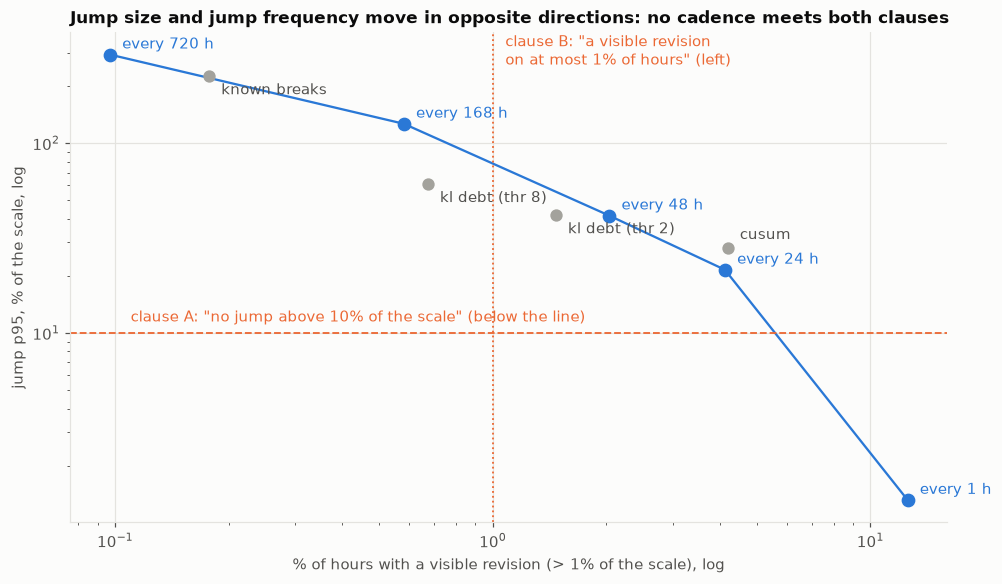

In [6]:
cal = {k: res[n] for k, n in [(720, "calendar k=720 (monthly)"), (168, "calendar k=168 (weekly)"), (48, "calendar k=48"),
                             (24, "calendar k=24 (daily)"), (1, "calendar k=1 (continuous)")]}
fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
xs = [100 * r["pct_visible"] for r in cal.values()]
ys = [100 * r["jump_p95"] for r in cal.values()]
ax.plot(xs, ys, color=viz.BLUE, marker="o", ms=8, lw=1.5)
for k, xv, yv in zip(cal, xs, ys):
    ax.annotate(f"every {k} h", (xv, yv), textcoords="offset points", xytext=(8, 4), color=viz.BLUE)
others = {"cusum": "cusum on realised error", "kl debt (thr 2)": "kl debt (thr 2)", "kl debt (thr 8)": "kl debt (thr 8)",
          "known breaks": "known breaks"}
for lab, n in others.items():
    r = res[n]
    ax.scatter(100 * r["pct_visible"], 100 * r["jump_p95"], color=viz.MUTED, s=50, zorder=3)
    off = (8, 6) if lab == "cusum" else (8, -12)
    ax.annotate(lab, (100 * r["pct_visible"], 100 * r["jump_p95"]), textcoords="offset points", xytext=off,
                color=viz.TEXT_2)
ax.axhline(10, color=viz.ORANGE, lw=1.2, ls="--")
ax.text(0.11, 11.5, 'clause A: "no jump above 10% of the scale" (below the line)', color=viz.ORANGE)
ax.axvline(1, color=viz.ORANGE, lw=1.2, ls=":")
ax.text(1.08, 380, 'clause B: "a visible revision\non at most 1% of hours" (left)', color=viz.ORANGE, va="top")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("% of hours with a visible revision (> 1% of the scale), log")
ax.set_ylabel("jump p95, % of the scale, log")
ax.set_title("Jump size and jump frequency move in opposite directions: no cadence meets both clauses")
export(fig, "stability_two_clauses"); plt.show()

Reading the figure: along the calendar curve, refitting more often makes each jump smaller (from 293% of the
scale monthly to 1.3% continuously) but makes jumps more frequent (from 0.1% to 12.6% of hours). Only continuous
refits stay under the 10% ceiling, and they are visible on 12.6% of hours; on the calendar curve, only weekly or
rarer refits stay left of the 1% wall, with jumps of 126% of the scale or more. The bottom-left corner, where both clauses hold, is
empty.

> **Takeaway.** A service contract can sign a clause on the *size* of revisions or on their *frequency*, not
> both. Writing which one is a business decision; leaving it unwritten means the scheduler picks one by default.

## 7. And the "best" policy depends on what stability costs

A composite objective prices the three families together: `J = MASE + lam_c x refits / 1000 + lam_k x churn`.

In [7]:
rows = ["| lam_c (cost of refits) | lam_k (cost of churn) | best policy | J |", "|---|---|---|---|"]
for lam_c, lam_k in ((0.0, 0.0), (0.05, 0.0), (0.05, 2.0), (0.05, 10.0), (0.20, 10.0), (0.05, 40.0)):
    name, r = min(res.items(), key=lambda kv: total_cost(kv[1], lam_c, lam_k))
    rows.append(f"| {lam_c:.2f} | {lam_k:.1f} | {name} | {total_cost(r, lam_c, lam_k):.4f} |")
display(Markdown("\n".join(rows)))

| lam_c (cost of refits) | lam_k (cost of churn) | best policy | J |
|---|---|---|---|
| 0.00 | 0.0 | calendar k=1 (continuous) | 0.8915 |
| 0.05 | 0.0 | calendar k=24 (daily) | 0.9085 |
| 0.05 | 2.0 | calendar k=24 (daily) | 0.9183 |
| 0.05 | 10.0 | cusum on realised error | 0.9548 |
| 0.20 | 10.0 | calendar k=48 | 0.9647 |
| 0.05 | 40.0 | cusum on realised error | 1.0488 |

With free refits and free churn, continuous wins; as soon as refits cost something, daily wins; once churn is
priced (lam_k >= 10), the CUSUM wins, although it is first on none of the three metrics taken alone.

> **Takeaway.** "Which cadence?" has no answer until the prices of compute and of instability are written down.
> Notebook 2 asks the next question: if a perfect detector loses, what exactly is it missing?